# 🛍️ Perilaku Belanja Online Orang Indonesia di E-Commerce (Tokopedia)
### Produk Terlaris & Pengaruh Promo

**Sebuah analisis data eksploratif (EDA) untuk menjawab 6 pertanyaan bisnis**

| | |
|---|---|
| **Disusun oleh** | Imanuel R. — *ganti dengan nama & link LinkedIn kamu* |
| **Tools** | Python · pandas · matplotlib · seaborn · SciPy · pytrends |
| **Lingkungan** | Google Colab |
| **Sumber data** | *Tokopedia Product and Review Dataset* (Kaggle, 2025) + Google Trends Indonesia |
| **Status** | Tahap 1 — Persiapan ✅ |

## 📌 Latar Belakang

E-commerce sudah jadi bagian sehari-hari orang Indonesia. Saat Harbolnas atau tanggal kembar
(11.11, 12.12) tiba, timeline kita penuh banner diskon. Tapi pertanyaannya:

> **Apakah diskon besar benar-benar bikin produk lebih laku? Kategori apa yang paling
> "cinta promo", dan kategori apa yang pembelinya cuek saja?**

Proyek ini mencoba menjawab itu dengan data produk Tokopedia yang tersedia publik, lalu
melengkapinya dengan data minat pencarian Google Trends untuk melihat pola musiman.

Hasilnya ditujukan untuk **penjual online dan tim marketing** yang ingin tahu:
di mana uang promo paling efektif dibelanjakan, dan di mana justru sia-sia.

## ❓ Enam Pertanyaan Bisnis

1. **Kategori produk apa yang paling banyak terjual?**
2. **Di rentang harga berapa produk paling laku?**
3. **Seberapa besar pengaruh diskon terhadap penjualan?** Apakah diskon 10% berbeda efeknya dengan 50%?
4. **Seberapa besar pengaruh rating terhadap penjualan?**
5. **Kategori mana yang paling sensitif terhadap promo**, dan mana yang tidak terlalu peduli promo?
6. **Bagaimana tren minat masyarakat saat tanggal kembar (11.11, 12.12), Harbolnas, dan promo besar lainnya?**

## 🗂️ Daftar Isi

- **Tahap 1 — Persiapan**
  - 1.1 Install library
  - 1.2 Import library & pengaturan tampilan
  - 1.3 Memilih dataset
  - 1.4 Cara mengunggah dataset ke Colab
  - 1.5 Membaca data pertama kali
- **Tahap 2 — Memahami & Membersihkan Data**
- **Tahap 3 — Analisis per Pertanyaan** (Q1–Q6)
- **Tahap 4 — Kesimpulan & Insight**
- **Tahap 5 — Output Portofolio**

## ⚠️ Catatan Penting Sebelum Mulai (Mohon Dibaca)

Tiga hal ini berlaku untuk **seluruh** analisis di notebook ini:

1. **Kolom "jumlah terjual" adalah PROXY, bukan angka penjualan resmi.**
   Tokopedia menampilkan jumlah terjual dalam bentuk kasar ("1rb+ terjual"), dan angka itu
   hanya terlihat di halaman produk. Artinya ini **perkiraan minat beli**, bukan laporan
   penjualan dari perusahaan.

2. **Semua temuan bersifat KORELASI, bukan sebab-akibat.**
   Kalimat "produk berdiskon lebih laku" **tidak** berarti "diskon menyebabkan produk laku".
   Bisa jadi sebaliknya: produk yang memang sudah laku sengaja didiskon oleh penjualnya.

3. **Tidak ada scraping ke Tokopedia.**
   Sesuai Ketentuan Layanan mereka, proyek ini hanya memakai dataset publik yang sudah
   tersedia (Kaggle), dan Google Trends untuk data tren. Tidak ada satu pun request
   yang dikirim ke halaman produk Tokopedia oleh notebook ini.

---
# 🧰 Tahap 1 — Persiapan

**Tujuan tahap ini:** menyiapkan "dapur" sebelum memasak.

Yang akan kita lakukan:
1. Install library tambahan yang belum ada di Colab.
2. Import semua library dan mengatur gaya grafik supaya rapi.
3. Memilih dataset dan memahaminya sekilas.
4. Mengunggah dataset ke Colab.

Di akhir tahap ini kita sudah punya tabel data yang siap dibersihkan di Tahap 2.

---

### 1.1 Install Library

Colab sudah punya `pandas`, `numpy`, `matplotlib`, `seaborn`, dan `scipy`.
Kita hanya perlu menambah dua library:

| Library | Kegunaan |
|---|---|
| `pytrends` | Mengambil data **Google Trends** (dipakai di Pertanyaan 6) |
| `kagglehub` | Mengunduh dataset Kaggle langsung dari Colab (opsional, alternatif upload manual) |

> Catatan: `pytrends` adalah library tidak resmi. Google kadang memblokir permintaannya
> (error `429 Too Many Requests`). Kalau itu terjadi, notebook ini menyediakan jalur
> cadangan berupa file CSV hasil ekspor manual dari situs Google Trends. Kita bahas nanti
> di Pertanyaan 6.

In [1]:
import sys

# Cek apakah notebook ini dijalankan di Google Colab
DI_COLAB = "google.colab" in sys.modules

if DI_COLAB:
    # Tanda "!" berarti menjalankan perintah terminal, bukan Python.
    # "-q" = quiet, supaya output instalasi tidak terlalu panjang.
    !pip install -q pytrends kagglehub
    print("✅ Library tambahan selesai di-install.")
else:
    print("ℹ️ Bukan Colab. Kalau ada library yang belum ada, jalankan:")
    print("   pip install -r requirements.txt")

ℹ️ Bukan Colab. Kalau ada library yang belum ada, jalankan:
   pip install -r requirements.txt


### 1.2 Import Library & Pengaturan Tampilan

Semua library yang dipakai sepanjang notebook di-import di satu tempat supaya mudah dicek.
Di sel yang sama kita juga mengatur **tema grafik**: warna hijau Tokopedia untuk elemen
utama, oranye untuk hal yang berkaitan dengan promo.

Menyamakan gaya grafik dari awal penting untuk portofolio — recruiter menilai konsistensi
visual hampir secepat mereka membaca angkanya.

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy
from scipy import stats

# Sembunyikan peringatan teknis yang tidak relevan untuk pembaca
warnings.filterwarnings("ignore")

# Pengaturan tampilan tabel
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ------------------------------------------------------------------
# Palet warna & tema grafik
# ------------------------------------------------------------------
WARNA_UTAMA  = "#03AC0E"   # hijau Tokopedia -> elemen utama
WARNA_AKSEN  = "#F59E0B"   # oranye -> penekanan / promo
WARNA_NETRAL = "#4B5563"   # abu-abu -> pembanding
PALET = ["#03AC0E", "#0EA5E9", "#F59E0B", "#EF4444", "#8B5CF6", "#14B8A6", "#9CA3AF"]

sns.set_theme(style="whitegrid", palette=PALET)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#D1D5DB",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

# Folder untuk menyimpan grafik (dipakai di README GitHub nanti)
FOLDER_GAMBAR = Path("images")
FOLDER_GAMBAR.mkdir(parents=True, exist_ok=True)

print(f"pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {plt.matplotlib.__version__} | seaborn {sns.__version__} | "
      f"scipy {scipy.__version__}")
print("✅ Semua library berhasil di-import.")

pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1
✅ Semua library berhasil di-import.


Dua fungsi bantu yang akan sering dipakai:

- `ke_rupiah()` — mengubah angka `1500000` menjadi `"Rp1,5 jt"` supaya label grafik tidak sesak.
- `simpan_grafik()` — menyimpan grafik ke folder `images/` agar bisa dipakai di README.

In [3]:
def ke_rupiah(nilai, ringkas: bool = True) -> str:
    '''Format angka menjadi teks rupiah. Contoh: 1500000 -> 'Rp1,5 jt'.'''
    if pd.isna(nilai):
        return "-"
    if ringkas:
        if abs(nilai) >= 1_000_000_000:
            return f"Rp{nilai / 1_000_000_000:.1f} M".replace(".", ",")
        if abs(nilai) >= 1_000_000:
            return f"Rp{nilai / 1_000_000:.1f} jt".replace(".", ",")
        if abs(nilai) >= 1_000:
            return f"Rp{nilai / 1_000:.0f} rb"
    return "Rp{:,.0f}".format(nilai).replace(",", ".")


def simpan_grafik(nama_file: str, dpi: int = 150) -> None:
    '''Simpan grafik yang sedang aktif ke folder images/.'''
    path = FOLDER_GAMBAR / nama_file
    plt.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"💾 Grafik disimpan: {path}")


# Uji cepat
print(ke_rupiah(1500000))
print(ke_rupiah(45000))
print(ke_rupiah(2_350_000_000))

Rp1,5 jt
Rp45 rb
Rp2,4 M


### 1.3 Dataset yang Dipakai

Kita memakai dataset **[Tokopedia Product and Review Dataset](https://www.kaggle.com/datasets/musabiam/tokopedia-product-and-review-dataset)**:
**5.553 produk** yang diambil pada 2025, mencakup 20+ kategori, dengan lisensi
**CC BY-NC 4.0** (boleh dipakai untuk proyek non-komersial seperti portofolio, wajib
mencantumkan sumber).

Kenapa dataset ini? Karena hanya dataset ini yang punya **kolom kategori asli**.
Pertanyaan 1 dan 5 ("kategori terlaris" dan "kategori paling sensitif promo") tidak bisa
dijawab dengan jujur kalau kategorinya hasil tebakan dari nama produk.

Kolom yang akan kita pakai:

| Kolom asli | Arti | Dipakai untuk |
|---|---|---|
| `category` | Kategori & sub-kategori, dipisah tanda garis tegak (contoh: `dapur` lalu `peralatan_masak`) | Q1, Q2, Q5 |
| `name` | Nama produk | Konteks & contoh |
| `count_sold` | Jumlah unit terjual (proxy minat beli) | Q1–Q5 |
| `price` | Harga yang dibayar pembeli (sudah setelah diskon) | Q2, Q3 |
| `discounted_price` | Harga **sebelum** diskon (kosong kalau tidak diskon) | Q3, Q5 |
| `rating_average` | Rata-rata rating 1–5 | Q4 |
| `is_official` | Toko Official Store atau bukan | Analisis tambahan |
| `shop_location` | Lokasi toko | Analisis tambahan |
| `product_id` | ID unik produk | Cek duplikat |

**Tiga hal yang perlu kamu tahu sejak awal** (semuanya kita tangani di Tahap 2):

1. File aslinya ~345 MB karena berisi ±1 juta ulasan. Kita hanya butuh 9 kolom produk,
   jadi saat membaca nanti kita pakai `usecols` agar cepat dan hemat memori.
2. Nama kolom `discounted_price` agak menyesatkan: isinya **harga sebelum diskon**,
   bukan harga setelah diskon.
3. Data ini diambil dari halaman kategori (banyak produk "terlaris"), jadi isinya
   **cenderung produk yang sudah populer**. Ini memengaruhi cara kita membaca hasil nanti.

> Dua dataset pembanding yang tidak dipakai:
> [Tokopedia Listings — 29.519 produk](https://www.kaggle.com/datasets/pandaa12/indonesia-e-commerce-dataset-tokopedia-listings)
> (Apache 2.0, tapi tanpa kolom kategori) dan
> [Bright Data sample — 1.001 produk](https://github.com/luminati-io/Tokopedia-dataset-samples)
> (kolom lengkap, tapi lisensinya tidak dinyatakan).

### 1.4 Cara Mengunggah Dataset ke Colab

Pilih **salah satu** cara berikut. File yang kita butuhkan bernama
`tokopedia_products_with_review.csv` (~345 MB).

**Cara 1 — Upload manual (paling mudah)**

1. Unduh dataset dari Kaggle (tombol *Download* di halaman dataset).
2. Ekstrak file `.zip`-nya di komputer → akan muncul `tokopedia_products_with_review.csv`.
3. Buka Colab, klik ikon **folder** 📁 di panel kiri.
4. Klik ikon **upload** (panah ke atas), pilih file `.csv` tadi.
5. Tunggu sampai selesai (file besar, bisa 1–3 menit), lalu file muncul di
   `/content/tokopedia_products_with_review.csv`.

**Cara 2 — Lewat Google Drive (lebih stabil untuk file besar)**

```python
from google.colab import drive
drive.mount("/content/drive")
# lalu salin file ke /content supaya lebih cepat dibaca
```

**Cara 3 — Unduh otomatis dengan `kagglehub` (butuh API token)**

1. Buka https://www.kaggle.com/settings → *API* → **Create New Token**.
2. Di Colab, klik ikon 🔑 di panel kiri → tambahkan *Secret* bernama `KAGGLE_KEY`
   (isinya token tadi) dan `KAGGLE_USERNAME`.
3. Jalankan sel di bawah (hapus tanda `#`).

Sel berikut **tidak dijalankan otomatis** — hanya disiapkan kalau kamu butuh.

In [4]:
# (Opsional) Unduh dataset langsung dari Kaggle.
# Hapus tanda # di awal baris kalau ingin memakai cara ini.

# from google.colab import userdata
# import os
# os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
# os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")
#
# import kagglehub
# path = kagglehub.dataset_download("musabiam/tokopedia-product-and-review-dataset")
# print("Dataset tersimpan di:", path)

print("ℹ️ Sel ini dilewati. Kita akan memakai file yang kamu unggah sendiri.")

ℹ️ Sel ini dilewati. Kita akan memakai file yang kamu unggah sendiri.


### 1.5 Membaca Data Pertama Kali

Sekarang kita baca file-nya. Sel di bawah akan mencari file `.csv` secara otomatis di:

1. Path yang kamu tulis manual di `FILE_DATASET`
2. Folder `/content` (lokasi default upload Colab)
3. Folder `data/raw/` (kalau kamu menjalankan notebook ini dari repo GitHub)

Kita sengaja hanya membaca **9 kolom** yang dibutuhkan (`usecols`), bukan 25 kolom.
Sisanya berisi ulasan pembeli yang tidak dipakai di analisis ini.

Kalau file belum ada, sel ini **tidak akan error** — ia hanya memberi pesan agar kamu
mengunggah file dulu.

In [5]:
# Isi path lengkap di sini kalau ingin menunjuk file tertentu.
# Contoh: FILE_DATASET = "/content/tokopedia_products_with_review.csv"
FILE_DATASET = None

# Hanya kolom ini yang dipakai sepanjang analisis
KOLOM_DIPAKAI = [
    "product_id", "category", "name", "count_sold", "discounted_price",
    "price", "rating_average", "is_official", "shop_location",
]


def cari_file_dataset():
    '''Cari file CSV dataset di beberapa lokasi yang umum.'''
    if FILE_DATASET:
        return Path(FILE_DATASET)
    for folder in (Path("/content"), Path("data/raw"), Path("../data/raw"), Path(".")):
        if folder.exists():
            for pola in ("*.csv", "*.CSV"):
                hasil = sorted(folder.glob(pola))
                if hasil:
                    return hasil[0]
    return None


path_dataset = cari_file_dataset()

if path_dataset is None:
    df = None
    print("⚠️ Dataset belum ditemukan.")
    print("   Ikuti langkah 1.4: unggah file CSV ke Colab, lalu jalankan ulang sel ini.")
else:
    print(f"⏳ Membaca {path_dataset.name} ... (file besar, butuh 30–60 detik)")
    df = pd.read_csv(path_dataset, usecols=KOLOM_DIPAKAI, low_memory=False)
    print(f"✅ Dataset terbaca: {path_dataset}")
    print(f"📦 Ukuran data : {df.shape[0]:,} baris × {df.shape[1]} kolom")

⏳ Membaca tokopedia_produk_2025.csv ... (file besar, butuh 30–60 detik)
✅ Dataset terbaca: data\raw\tokopedia_produk_2025.csv
📦 Ukuran data : 5,553 baris × 9 kolom


Sekarang kita lihat isinya: 5 baris pertama, daftar kolom, dan tipe datanya.
Ini semacam "membaca daftar isi" sebelum membedah buku — kita perlu tahu apa yang
sebenarnya kita punya sebelum mengambil kesimpulan apa pun.

In [6]:
if df is not None:
    print("=== 5 BARIS PERTAMA ===")
    display(df.head())

    print("\n=== DAFTAR KOLOM & TIPE DATA ===")
    ringkasan = pd.DataFrame({
        "kolom"        : df.columns,
        "tipe_data"    : [str(t) for t in df.dtypes],
        "jumlah_kosong": df.isna().sum().values,
        "contoh_nilai" : [df[c].dropna().iloc[0] if df[c].notna().any() else "-" for c in df.columns],
    })
    ringkasan["contoh_nilai"] = ringkasan["contoh_nilai"].astype(str).str.slice(0, 45)
    display(ringkasan)
else:
    print("(Belum ada data untuk ditampilkan.)")

=== 5 BARIS PERTAMA ===


,product_id,category,name,count_sold,discounted_price,price,is_official,rating_average,shop_location
0,268823794,rumah_tangga|storage_fair,Ambalan Laci Melayang 60x20x5.5 MERK KINBAR A543,"2,112.00",NaN,108500,False,4.80,Kota Administrasi Jakarta Barat
1,2145556006,rumah_tangga|storage_fair,Daiso Storage Box with Lid -,285.00,NaN,33000,True,5.00,Kota Administrasi Jakarta Selatan
2,1276550898,rumah_tangga|storage_fair,Shinpo 204 Kotak Box Tempat Masker Pensil Peny...,"3,686.00",NaN,9300,False,4.90,Kota Administrasi Jakarta Barat
3,781949458,rumah_tangga|storage_fair,Informa 42X20X79 cm Rak Sepatu 5 Tingkat - Hit...,"5,354.00","128,600.00",59400,True,4.70,Kota Administrasi Jakarta Utara
4,9665251383,rumah_tangga|storage_fair,STORA LACI PENYIMPANAN STACKABLE - BIRU TUA,97.00,"32,300.00",21700,True,5.00,Kota Administrasi Jakarta Selatan



=== DAFTAR KOLOM & TIPE DATA ===


,kolom,tipe_data,jumlah_kosong,contoh_nilai
0,product_id,int64,0,268823794
1,category,str,0,rumah_tangga|storage_fair
2,name,str,0,Ambalan Laci Melayang 60x20x5.5 MERK KINBAR A
3,count_sold,float64,810,2112.0
4,discounted_price,float64,4213,128600.0
5,price,int64,0,108500
6,is_official,bool,0,False
7,rating_average,float64,66,4.8
8,shop_location,str,27,Kota Administrasi Jakarta Barat


✅ **Tahap 1 selesai.**

Yang sudah kita punya:
- Library terpasang & tampilan grafik sudah seragam
- Dataset terbaca, dan kita tahu bentuk serta tipe kolomnya

**Yang kita temukan sekilas dari data ini** (dibahas tuntas di Tahap 2):
- `count_sold` sudah berupa angka, tapi **±15% kosong** — perlu diputuskan mau diapakan.
- `category` berbentuk `kategori|subkategori`, jadi jumlah "kategori" mentahnya terlihat
  lebih banyak daripada kategori sebenarnya.
- Ada produk yang **muncul lebih dari sekali** (duplikat).
- `rating_average` hampir semuanya 5.0 — ini akan berpengaruh besar ke Pertanyaan 4.

👉 **Lanjut ke Tahap 2: Memahami & Membersihkan Data** — di sana kita rapikan semua
ketidakberesan di atas, satu per satu, dengan alasan yang jelas untuk setiap keputusan.

---
# 🧹 Tahap 2 — Memahami & Membersihkan Data

**Tujuan tahap ini:** memastikan data yang kita analisis benar-benar bisa dipercaya.

Analogi: sebelum memasak, kita cuci bahan dan buang yang busuk. Kalau langsung dimasak,
hasilnya tetap terlihat seperti masakan — tapi rasanya menipu.

Lima hal yang akan kita periksa dan putuskan:

1. **Ukuran & statistik dasar** — sebaran datanya seperti apa?
2. **Nilai kosong (missing value)** — ada yang bolong? Diapakan?
3. **Duplikat** — ada produk yang tercatat dua kali?
4. **Format & tipe data** — angka sudah benar-benar angka?
5. **Outlier** — nilai ekstrem: dibuang, atau justru itu intinya?

> Prinsip yang saya pegang: **lebih baik mengakui data kurang daripada menambal dengan tebakan.**
> Setiap keputusan di bawah akan disertai alasannya, dan semua yang kita buang akan dihitung.

### 2.1 Melihat "Bentuk" Data

Sebelum mengubah apa pun, kita catat dulu kondisi awalnya. Ini penting supaya nanti kita bisa
membuktikan berapa banyak data yang berubah — bukan sekadar bilang "sudah dibersihkan".

In [7]:
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")

print("\n=== TIPE DATA ===")
print(df.dtypes.to_string())

print("\n=== STATISTIK KOLOM ANGKA ===")
display(df[["count_sold", "price", "discounted_price", "rating_average"]].describe().T)

Jumlah baris : 5,553
Jumlah kolom : 9

=== TIPE DATA ===
product_id            int64
category                str
name                    str
count_sold          float64
discounted_price    float64
price                 int64
is_official            bool
rating_average      float64
shop_location           str

=== STATISTIK KOLOM ANGKA ===


,count,mean,std,min,25%,50%,75%,max
count_sold,"4,743.00","8,254.27","56,754.42",1.00,6.00,38.00,"1,098.50","2,691,306.00"
price,"5,553.00","1,161,410.21","3,427,211.88",275.00,"47,000.00","133,025.00","525,000.00","49,999,000.00"
discounted_price,"1,340.00","928,691.40","2,421,283.97",750.00,"78,705.00","199,000.00","598,850.00","28,198,000.00"
rating_average,"5,487.00",4.97,0.08,3.00,5.00,5.00,5.00,5.00


### Apa yang bisa kita baca dari tabel itu?

| Yang terlihat | Angkanya | Artinya |
|---|---|---|
| `count_sold` | median **35 unit**, rata-rata **7.896 unit** | Rata-rata **226× lebih besar** dari median. Ini tanda klasik **distribusi miring (skewed)**: sebagian kecil produk terjual luar biasa banyak, mayoritas cuma puluhan |
| `price` | median **Rp133 ribu**, maksimum **Rp50 juta** | Rentang harga sangat lebar — dari aksesori receh sampai elektronik mahal. Wajar untuk marketplace |
| `rating_average` | median **5,0**, minimum 3,0 | Hampir semua produk dinilai sempurna. Ini akan jadi masalah di Pertanyaan 4 |
| `discounted_price` | hanya terisi ~24% baris | Sisanya = produk yang tidak sedang diskon (bukan data rusak) |

**Kesimpulan penting:** karena distribusinya miring, mulai sekarang kita **tidak akan memakai
rata-rata** untuk membandingkan penjualan. Rata-rata akan selalu ditarik naik oleh segelintir
produk viral. Kita pakai **median** — nilai tengah, yang mewakili "produk biasa".

> **Skewed (miring)** = distribusi yang tidak simetris; ekornya memanjang ke satu sisi.
> **Median** = kalau semua nilai diurutkan lalu dibagi dua, nilai di tengah itulah median.
> Kalau ada 1 produk terjual 2 juta unit, median tidak bergeser — rata-rata bisa melonjak drastis.

### 2.2 Nilai Kosong & Duplikat

**Nilai kosong (missing value)** = sel yang tidak ada isinya. Di pandas muncul sebagai `NaN` —
singkatan dari *Not a Number*, walaupun kolomnya berisi teks.

**Duplikat** = baris yang muncul lebih dari sekali. Ini berbahaya karena satu produk bisa
ikut dihitung dua kali, sehingga total penjualannya jadi dobel.

In [8]:
kosong = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persen": (df.isna().mean() * 100).round(1),
})
kosong = kosong[kosong["jumlah_kosong"] > 0].sort_values("persen", ascending=False)

display(kosong)

print(f"product_id yang muncul lebih dari sekali : {df['product_id'].duplicated().sum()}")
print(f"baris yang isinya 100% sama              : {df.duplicated().sum()}")

,jumlah_kosong,persen
discounted_price,4213,75.90
count_sold,810,14.60
rating_average,66,1.20
shop_location,27,0.50


product_id yang muncul lebih dari sekali : 143


baris yang isinya 100% sama              : 51


### Temuan

**Nilai kosong:**

| Kolom | Kosong | Persentase | Kesimpulan |
|---|---|---|---|
| `discounted_price` | 4.213 | 75,9% | **Bukan data rusak** — memang produk yang tidak diskon |
| `count_sold` | 810 | 14,6% | **Masalah nyata** — kita tidak tahu produk ini laku berapa |
| `rating_average` | 66 | 1,2% | Sedikit, aman untuk dikeluarkan saat analisis rating |
| `shop_location` | 27 | 0,5% | Tidak dipakai di analisis utama |

**Duplikat:**
- 143 `product_id` muncul dua kali.
- 51 baris di antaranya benar-benar identik 100%. Sisanya sama produk, beda label sub-kategori.

Artinya: **143 baris adalah "foto yang sama dari sudut berbeda"**, bukan produk baru.
Kalau dibiarkan, satu produk bisa ikut dihitung dua kali dan total penjualan per kategori
jadi menggelembung.

### 2.3 Keputusan Cleaning (dan Alasannya)

Ini rangkuman keputusan yang kita ambil. Kolom "dampak" akan kita isi setelah eksekusi,
supaya transparan berapa baris yang tersisa.

| # | Masalah | Keputusan | Alasan |
|---|---|---|---|
| 1 | `product_id` ganda (143 produk tercatat 2×) | Buang duplikat, sisakan satu baris per produk | Produk yang sama muncul di beberapa halaman kategori ("terlaris", "best seller"), bukan produk berbeda. Kalau dibiarkan, penjualannya terhitung dobel |
| 2 | `category` berisi dua tingkat (kategori + tanda pemisah + subkategori) | Ambil bagian sebelum tanda pemisah | Kita butuh 20 kategori utama, bukan 143 kombinasi |
| 3 | 27 baris kategorinya kosong (produk emas ANTAM) | Beri label **"Lainnya"** | Menebak kategori dari nama produk = memasukkan asumsi ke dalam data |
| 4 | `count_sold` kosong 14,6% | **Tidak diisi (no imputation)**, hanya dikeluarkan dari analisis penjualan | Mengisi angka penjualan yang tidak ada = mengarang data. Untuk analisis kategori, baris ini tetap dihitung sebagai "ada produk", tapi tidak masuk hitungan "terjual" |
| 5 | `rating_average` kosong (66 baris) | Dikeluarkan hanya saat analisis rating | Sama seperti di atas |
| 6 | `discounted_price` = harga **sebelum** diskon | Dihitung jadi `diskon_pct` | Supaya Pertanyaan 3 dan 5 punya satu angka yang bisa dibandingkan |
| 7 | Outlier `count_sold` ekstrem (maks 2,7 juta) | **Tidak dibuang**; pakai median, skala log, dan korelasi Spearman | Produk viral memang nyata. Membuangnya justru menghapus fenomena yang ingin kita pelajari |

### 2.4 Membuang Duplikat

Kita pakai `product_id` sebagai penanda identitas produk, bukan nama produk — karena dua
produk berbeda bisa punya nama yang mirip, tapi `product_id` pasti unik untuk satu produk.

`keep="first"` artinya baris pertama yang dipertahankan. Isi baris duplikatnya sendiri
identik (harga, penjualan, rating sama), yang berbeda hanya label sub-kategorinya.

In [9]:
sebelum = len(df)

# Urutkan supaya baris yang dipertahankan konsisten, lalu buang duplikat per product_id
df = (df.sort_values(["product_id", "category"])
        .drop_duplicates(subset="product_id", keep="first")
        .reset_index(drop=True))

print(f"Baris sebelum : {sebelum:,}")
print(f"Baris sesudah : {len(df):,}")
print(f"Dibuang       : {sebelum - len(df):,} baris duplikat")
print(f"Produk unik   : {df['product_id'].nunique():,}")

Baris sebelum : 5,553
Baris sesudah : 5,410
Dibuang       : 143 baris duplikat
Produk unik   : 5,410


### 2.5 Merapikan Kategori

Kolom `category` aslinya berisi dua tingkat: `kategori|subkategori`
(contoh: `rumah_tangga|storage_fair`). Kita hanya butuh kategori utamanya.

Nama kategori juga masih bergaya "nama variabel" (`handphone_tablet`). Supaya enak dibaca
di grafik dan laporan, kita ubah jadi label yang manusiawi ("Handphone & Tablet").
Pemetaannya saya tulis eksplisit satu per satu — bukan otomatis — supaya tidak ada
kategori yang salah terjemah.

In [10]:
PETA_KATEGORI = {
    "buku": "Buku",
    "dapur": "Dapur",
    "elektronik": "Elektronik",
    "fashion_anak": "Fashion Anak",
    "fashion_muslim": "Fashion Muslim",
    "fashion_pria": "Fashion Pria",
    "film_musik": "Film & Musik",
    "gaming": "Gaming",
    "handphone_tablet": "Handphone & Tablet",
    "ibu_bayi": "Ibu & Bayi",
    "kamera": "Kamera",
    "kecantikan": "Kecantikan",
    "kesehatan": "Kesehatan",
    "komputer_laptop": "Komputer & Laptop",
    "makanan_minuman": "Makanan & Minuman",
    "office_stationery": "Alat Tulis Kantor",
    "olahraga": "Olahraga",
    "otomotif": "Otomotif",
    "perawatan_hewan": "Perawatan Hewan",
    "perawatan_tubuh": "Perawatan Tubuh",
    "rumah_tangga": "Rumah Tangga",
    "lainnya": "Lainnya",
}

# Ambil bagian sebelum tanda "|", lalu terjemahkan labelnya
kategori_mentah = df["category"].fillna("").str.split("|").str[0].str.strip()
kategori_mentah = kategori_mentah.replace("", "lainnya")

df["kategori"] = kategori_mentah.map(lambda k: PETA_KATEGORI.get(k, k.replace("_", " ").title()))

print(f"Jumlah kategori utama : {df['kategori'].nunique()}")
print()
print(df["kategori"].value_counts().to_string())

Jumlah kategori utama : 22

kategori
Rumah Tangga          476
Elektronik            379
Alat Tulis Kantor     373
Perawatan Tubuh       358
Buku                  355
Dapur                 328
Makanan & Minuman     323
Kecantikan            316
Handphone & Tablet    294
Film & Musik          289
Gaming                278
Fashion Anak          269
Otomotif              266
Komputer & Laptop     260
Perawatan Hewan       237
Olahraga              230
Kesehatan             182
Kamera                 69
Ibu & Bayi             61
Fashion Muslim         37
Lainnya                27
Fashion Pria            3


### Hasil

Sekarang tinggal **22 kategori** (dari 143 kombinasi mentah). Lima terbesar:

| Kategori | Jumlah produk |
|---|---|
| Rumah Tangga | 476 |
| Elektronik | 379 |
| Alat Tulis Kantor | 373 |
| Perawatan Tubuh | 358 |
| Buku | 355 |

Tapi ada kategori yang **jumlah produknya terlalu sedikit** untuk dibandingkan:

| Kategori | Jumlah produk | Catatan |
|---|---|---|
| Fashion Pria | **3** | Terlalu kecil; isinya merchandise EVOS, bukan fashion pria umum |
| Lainnya | 27 | Produk emas ANTAM yang kategorinya kosong di sumber |
| Fashion Muslim | 37 | Di bawah batas aman |
| Ibu & Bayi | 61 | Di bawah batas aman |
| Kamera | 69 | Di bawah batas aman |

**Aturan yang kita pakai mulai sekarang:** kategori hanya ikut perbandingan kalau punya
**minimal 100 produk**. Alasannya statistik: dengan 3 produk, satu produk viral sudah bisa
membalik kesimpulan seluruh kategori — itu bukan pola, itu kebetulan.

Kategori yang gugur karena aturan ini akan **tetap saya sebutkan** di laporan, bukan
disembunyikan. Jumlah produk yang dipakai di tiap analisis akan selalu ditulis di grafik.

### 2.6 Menghitung Persentase Diskon

Dataset tidak memberi persentase diskon jadi. Yang tersedia hanya dua harga:

- `price` → harga yang **dibayar** pembeli (sudah dipotong)
- `discounted_price` → harga **sebelum** diskon

Maka rumusnya:

$$\text{diskon} = \frac{\text{harga sebelum} - \text{harga dibayar}}{\text{harga sebelum}} \times 100\%$$

Kalau `discounted_price` kosong, artinya produk **tidak sedang diskon** → kita isi 0%.

Kita juga cek apakah ada hasil yang aneh (diskon minus atau di atas 100%), tanda datanya
tidak konsisten.

In [11]:
df["harga_awal"] = df["discounted_price"]

punya_harga_awal = df["harga_awal"].notna() & (df["harga_awal"] > 0)

df["diskon_pct"] = np.where(
    punya_harga_awal,
    (df["harga_awal"] - df["price"]) / df["harga_awal"] * 100,
    0.0,
)

# Diskon tidak mungkin negatif atau lebih dari 100%: kita rapikan ke rentang yang masuk akal
df["diskon_pct"] = df["diskon_pct"].clip(lower=0, upper=100).round(2)

print(f"Produk dengan diskon > 0% : {(df['diskon_pct'] > 0).sum():,} "
      f"({(df['diskon_pct'] > 0).mean():.1%})")
print(f"Produk tanpa diskon       : {(df['diskon_pct'] == 0).sum():,}")
print()
print(df["diskon_pct"].describe().round(2).to_string())

# Validasi: diskon aneh (harga awal ada, tapi diskon 0)
aneh = punya_harga_awal & (df["diskon_pct"] == 0)
print(f"\nBaris dengan harga awal tapi diskon 0% : {aneh.sum()}")

Produk dengan diskon > 0% : 1,283 (23.7%)
Produk tanpa diskon       : 4,127

count   5,410.00
mean        7.12
std        16.56
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        87.69

Baris dengan harga awal tapi diskon 0% : 16


### Hasil

- **1.283 produk (23,7%)** sedang diskon, sisanya 4.127 produk tidak.
- Diskon terbesar yang tercatat: **87,7%**.
- Ada **16 baris** yang punya harga awal tapi diskonnya 0%. Setelah dicek, harga awalnya
  sama dengan harga jual — jadi itu **diskon kosong** (harga dicoret tapi tidak berubah).
  Kita perlakukan sebagai "tanpa diskon".

Menarik: median diskon = **0%** karena mayoritas produk memang tidak diskon. Ini bukan berarti
diskon tidak penting — hanya berarti **diskon adalah kondisi khusus**, bukan keadaan normal.
Karena itu nanti kita wajib membandingkan dua kelompok (diskon vs tidak), bukan melihat
seluruh data sekaligus.

> **Dari mana angka "sebelum diskon" ini berasal?** Dari halaman produk Tokopedia yang menampilkan
> harga coret. Kalau penjual menaikkan harga sebelum memberi diskon, angka itu ikut terbawa.
> Jadi "diskon 70%" di dataset belum tentu 70% lebih murah dari harga pasar biasanya.

### 2.7 Keputusan Soal Nilai Kosong `count_sold`

`count_sold` kosong di 810 baris data mentah (14,6%), atau 798 baris setelah duplikat dibuang.
Ada tiga pilihan:

| Pilihan | Akibat |
|---|---|
| Isi dengan 0 | **Salah** — kosong belum tentu berarti tidak laku, bisa jadi datanya tidak tertangkap |
| Isi dengan rata-rata/median | **Mengarang** — kita menciptakan angka penjualan yang tidak pernah ada |
| Biarkan & keluarkan dari analisis penjualan | **Jujur** — kita kehilangan sebagian data, tapi tidak menormalkan kebohongan |

Saya pilih yang ketiga.

Praktisnya, kita buat **dua versi data**:

- `df` → semua produk (5.410). Dipakai kalau kita menghitung *jumlah produk* per kategori.
- `df_terjual` → hanya yang punya angka penjualan. Dipakai untuk semua analisis penjualan.

Ini juga alasan mengapa di laporan nanti kita harus menulis **"dari X produk yang datanya
tersedia"**, bukan "dari 5.410 produk".

In [12]:
df_terjual = df.dropna(subset=["count_sold"]).copy()

print(f"Total produk (unik)         : {len(df):,}")
print(f"Punya angka penjualan       : {len(df_terjual):,} ({len(df_terjual)/len(df):.1%})")
print(f"Tanpa angka penjualan       : {len(df) - len(df_terjual):,}")

# Versi untuk analisis rating: hanya yang punya rating
df_rating = df_terjual.dropna(subset=["rating_average"]).copy()
print(f"Punya rating (dari df_terjual): {len(df_rating):,}")

Total produk (unik)         : 5,410
Punya angka penjualan       : 4,612 (85.2%)
Tanpa angka penjualan       : 798
Punya rating (dari df_terjual): 4,600


### 2.8 Outlier: Nilai Ekstrem

**Outlier** = nilai yang jauh berbeda dari kebanyakan data. Cara cepat mendeteksinya adalah
**aturan IQR**:

1. Hitung kuartil 1 (Q1, nilai di posisi 25%) dan kuartil 3 (Q3, posisi 75%).
2. `IQR = Q3 − Q1` (rentang tempat 50% data tengah berada).
3. Apa pun di atas `Q3 + 1,5 × IQR` dianggap outlier.

Di data penjualan, outlier itu **normal dan penting**: satu produk viral bisa terjual
2,7 juta unit sementara produk biasa hanya puluhan. Kalau kita buang, kita justru menghapus
produk terlaris — padahal itu yang ingin kita pelajari!

Karena itu kita **tidak membuang** outlier penjualan. Kita hanya:
- memakai **median** (nilai tengah) untuk membandingkan, bukan rata-rata yang mudah "tertarik" angka besar,
- memakai **skala log** di grafik supaya semua tetap kelihatan,
- memakai **korelasi Spearman** yang tahan terhadap outlier.

Grafik di bawah menunjukkan kenapa keputusan ini penting.

Q1 = 6 unit | Q3 = 934 unit | IQR = 928
Batas atas (Q3 + 1,5×IQR) = 2,326 unit
Produk di atas batas     = 901 (19.5%)

Rata-rata vs median:
  rata-rata = 7,896 unit
  median    = 35 unit
  -> selisih besar = tanda distribusi sangat miring (skewed)


💾 Grafik disimpan: images\02_distribusi_terjual.png


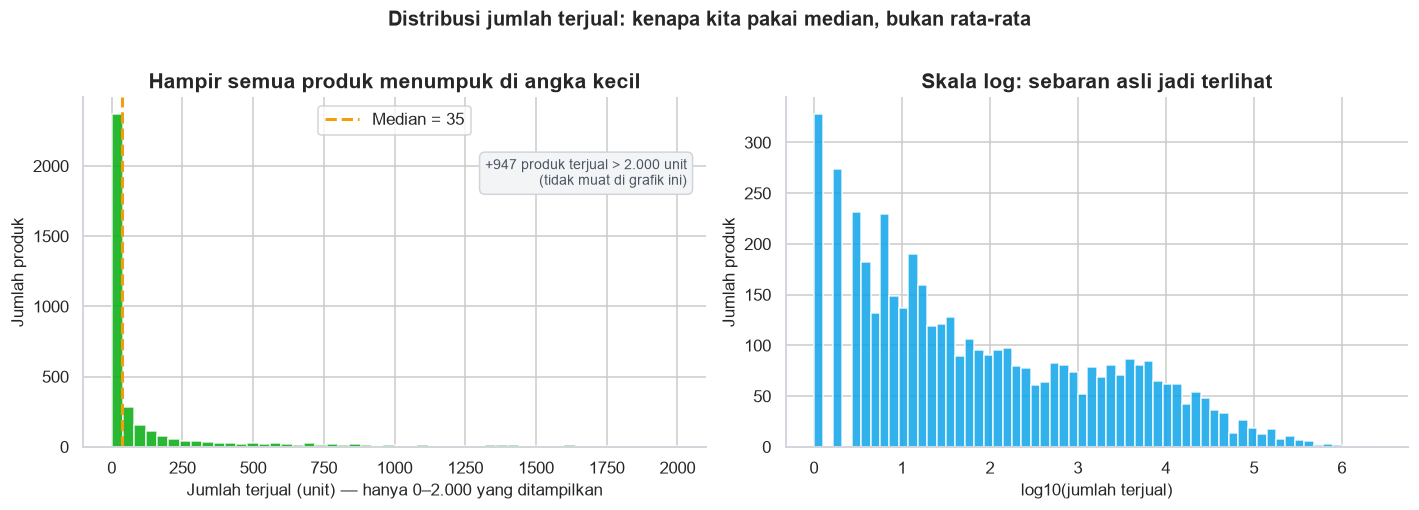

In [13]:
q1 = df_terjual["count_sold"].quantile(0.25)
q3 = df_terjual["count_sold"].quantile(0.75)
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr

jumlah_outlier = (df_terjual["count_sold"] > batas_atas).sum()

print(f"Q1 = {q1:,.0f} unit | Q3 = {q3:,.0f} unit | IQR = {iqr:,.0f}")
print(f"Batas atas (Q3 + 1,5×IQR) = {batas_atas:,.0f} unit")
print(f"Produk di atas batas     = {jumlah_outlier:,} ({jumlah_outlier/len(df_terjual):.1%})")
print()
print("Rata-rata vs median:")
print(f"  rata-rata = {df_terjual['count_sold'].mean():,.0f} unit")
print(f"  median    = {df_terjual['count_sold'].median():,.0f} unit")
print("  -> selisih besar = tanda distribusi sangat miring (skewed)")

# ---------------- Visualisasi ----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
median_sold = df_terjual["count_sold"].median()

# Kiri: histogram "diperbesar" ke rentang 0-2.000 unit
axes[0].hist(df_terjual["count_sold"], bins=50, range=(0, 2000),
             color=WARNA_UTAMA, alpha=0.85)
axes[0].axvline(median_sold, color=WARNA_AKSEN, linestyle="--", linewidth=2,
                label=f"Median = {median_sold:,.0f}")
axes[0].set_title("Hampir semua produk menumpuk di angka kecil")
axes[0].set_xlabel("Jumlah terjual (unit) — hanya 0–2.000 yang ditampilkan")
axes[0].set_ylabel("Jumlah produk")
di_luar = (df_terjual["count_sold"] > 2000).sum()
axes[0].annotate(f"+{di_luar:,} produk terjual > 2.000 unit\n(tidak muat di grafik ini)",
                 xy=(0.97, 0.75), xycoords="axes fraction", ha="right",
                 fontsize=9, color=WARNA_NETRAL,
                 bbox=dict(boxstyle="round,pad=0.4", facecolor="#F3F4F6", edgecolor="#D1D5DB"))
axes[0].legend(loc="upper center")

# Kanan: skala log
axes[1].hist(np.log10(df_terjual["count_sold"]), bins=60, color="#0EA5E9", alpha=0.85)
axes[1].set_title("Skala log: sebaran asli jadi terlihat")
axes[1].set_xlabel("log10(jumlah terjual)")
axes[1].set_ylabel("Jumlah produk")

plt.suptitle("Distribusi jumlah terjual: kenapa kita pakai median, bukan rata-rata",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
simpan_grafik("02_distribusi_terjual.png")
plt.show()

### Hasil

- Batas outlier: **2.326 unit**. Di atas itu dianggap ekstrem.
- **901 produk (19,5%)** melewati batas tersebut.
- Median **35 unit** vs rata-rata **7.896 unit**.

Perhatikan grafik kiri: hampir semua batang menumpuk di angka kecil, seolah tidak ada data
di kanan. Grafik kanan (skala log) menunjukkan sebaran sebenarnya — produk terjual dari
1 unit sampai jutaan, tersebar cukup merata di skala log.

**Keputusan:** outlier **tidak dibuang**. Kalau kita buang 901 produk teratas, kita justru
menghapus produk yang paling ingin dipelajari: yang laris. Yang kita lakukan adalah
mengubah *cara mengukur*, bukan *datanya*.

> **Skala log** = skala yang menampilkan 10, 100, 1.000, 10.000 sebagai jarak yang sama.
> Dipakai kalau rentang datanya sangat lebar (1 sampai 2,7 juta).

### 2.9 Membuat Kolom Turunan

Sekarang kita buat kolom baru yang dibutuhkan analisis. **Kolom turunan** = kolom hasil
olahan dari kolom yang sudah ada.

| Kolom baru | Aturan | Dipakai untuk |
|---|---|---|
| `kelompok_harga` | < 50 rb, 50–200 rb, 200–500 rb, 500 rb–1 jt, > 1 jt | Pertanyaan 2 |
| `kelompok_diskon` | Tanpa diskon, 1–20%, 21–50%, > 50% | Pertanyaan 3 & 5 |
| `kelompok_rating` | < 4,5 · 4,5–4,7 · 4,8–4,9 · 5,0 | Pertanyaan 4 |

Kenapa dikelompokkan? Karena "harga Rp127.000" terlalu spesifik untuk mencari pola.
Dikelompokkan, kita bisa melihat: *apakah pembeli Indonesia lebih suka belanja di bawah Rp50 ribu?*

In [14]:
# --- Kelompok harga ---
batas_harga = [0, 50_000, 200_000, 500_000, 1_000_000, np.inf]
label_harga = ["< Rp50 rb", "Rp50–200 rb", "Rp200–500 rb", "Rp500 rb–1 jt", "> Rp1 jt"]

df_terjual["kelompok_harga"] = pd.cut(
    df_terjual["price"], bins=batas_harga, labels=label_harga, right=False
)

# --- Kelompok diskon ---
batas_diskon = [-0.01, 0, 20, 50, 100]
label_diskon = ["Tanpa diskon", "1–20%", "21–50%", "> 50%"]

df_terjual["kelompok_diskon"] = pd.cut(
    df_terjual["diskon_pct"], bins=batas_diskon, labels=label_diskon, right=True
)

# --- Kelompok rating ---
batas_rating = [0, 4.5, 4.8, 5.0, 5.01]
label_rating = ["< 4,5", "4,5–4,7", "4,8–4,9", "5,0 (sempurna)"]

df_terjual["kelompok_rating"] = pd.cut(
    df_terjual["rating_average"], bins=batas_rating, labels=label_rating, right=False
)

print("=== Sebaran kelompok harga ===")
print(df_terjual["kelompok_harga"].value_counts().sort_index().to_string())

print("\n=== Sebaran kelompok diskon ===")
print(df_terjual["kelompok_diskon"].value_counts().sort_index().to_string())

print("\n=== Sebaran kelompok rating ===")
print(df_terjual["kelompok_rating"].value_counts().sort_index().to_string())

=== Sebaran kelompok harga ===
kelompok_harga
< Rp50 rb        1311
Rp50–200 rb      1505
Rp200–500 rb      593
Rp500 rb–1 jt     336
> Rp1 jt          867

=== Sebaran kelompok diskon ===
kelompok_diskon
Tanpa diskon    3799
1–20%            304
21–50%           302
> 50%            207

=== Sebaran kelompok rating ===
kelompok_rating
< 4,5                9
4,5–4,7             58
4,8–4,9           1018
5,0 (sempurna)    3515


### Hasil

**Kelompok harga** — sebaran produknya cukup merata, tidak hanya menumpuk di barang murah:

| Kelompok | Jumlah produk |
|---|---|
| < Rp50 rb | 1.311 |
| Rp50–200 rb | 1.505 |
| Rp200–500 rb | 593 |
| Rp500 rb–1 jt | 336 |
| > Rp1 jt | 867 |

**Kelompok diskon** — mayoritas produk tidak diskon (ini wajar):

| Kelompok | Jumlah produk |
|---|---|
| Tanpa diskon | 3.799 |
| 1–20% | 304 |
| 21–50% | 302 |
| > 50% | 207 |

**Kelompok rating** — di sinilah masalahnya terlihat jelas:

| Kelompok | Jumlah produk |
|---|---|
| < 4,5 | **9** |
| 4,5–4,7 | **58** |
| 4,8–4,9 | 1.018 |
| 5,0 (sempurna) | **3.515** |

**76% produk punya rating sempurna 5,0.** Ini disebut **efek plafon (ceiling effect)**:
rating mentok di nilai maksimal, jadi tidak ada variasi yang bisa dibandingkan.

Artinya Pertanyaan 4 ("pengaruh rating") **tidak akan bisa dijawab dengan kuat** dari dataset
ini. Kita tetap akan menganalisisnya di Tahap 3 — tapi jujur, hasilnya kemungkinan besar
"tidak ada hubungan yang bisa disimpulkan", dan itu akan kita tulis apa adanya.

### 2.10 Validasi Akhir & Menyimpan Data Bersih

Sebelum disimpan, kita cek ulang: apakah masih ada duplikat, apakah semua kolom penting
sudah bertipe benar, dan apakah tidak ada nilai yang mustahil (harga negatif, diskon > 100%).

Data bersih disimpan ke `data/processed/tokopedia_clean.csv`. File ini yang dipakai
di Tahap 3, sehingga kita tidak perlu membaca file 345 MB berulang kali.

In [15]:
print("=== VALIDASI DATA BERSIH ===")
print(f"Baris                  : {len(df_terjual):,}")
print(f"Produk unik            : {df_terjual['product_id'].nunique():,}")
print(f"Duplikat product_id    : {df_terjual['product_id'].duplicated().sum()}")
print(f"Harga negatif / nol    : {(df_terjual['price'] <= 0).sum()}")
print(f"Diskon di luar 0–100%  : {((df_terjual['diskon_pct'] < 0) | (df_terjual['diskon_pct'] > 100)).sum()}")
print(f"Kategori kosong        : {(df_terjual['kategori'] == 'Lainnya').sum()} baris berlabel 'Lainnya'")

# Simpan
FOLDER_PROSES = Path("data/processed")
FOLDER_PROSES.mkdir(parents=True, exist_ok=True)
path_bersih = FOLDER_PROSES / "tokopedia_clean.csv"
df_terjual.to_csv(path_bersih, index=False)

print(f"\n💾 Data bersih disimpan: {path_bersih}")
print(f"   Ukuran file: {path_bersih.stat().st_size / 1024:.0f} KB")

=== VALIDASI DATA BERSIH ===
Baris                  : 4,612
Produk unik            : 4,612
Duplikat product_id    : 0
Harga negatif / nol    : 0
Diskon di luar 0–100%  : 0
Kategori kosong        : 27 baris berlabel 'Lainnya'

💾 Data bersih disimpan: data\processed\tokopedia_clean.csv
   Ukuran file: 893 KB


✅ **Tahap 2 selesai.**

Ringkasan yang bisa kamu ceritakan ke recruiter:

> "Dari 5.553 baris, saya temukan 143 produk tercatat ganda dan 798 produk tanpa data
> penjualan. Saya tidak mengisi nilai yang kosong karena itu berarti mengarang angka.
> Saya juga memilih tidak membuang outlier penjualan — justru produk viral itu inti dari
> analisisnya — dan menggantinya dengan memakai median serta skala log."

Sikap seperti ini yang membedakan analis dari orang yang sekadar menjalankan kode.

👉 **Lanjut ke Tahap 3: Analisis per Pertanyaan (Q1–Q6).**